In [27]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/krishd123/high-dimensional-datascape/all_data.csv


In [28]:
df = pd.read_csv('/kaggle/input/datasets/krishd123/high-dimensional-datascape/all_data.csv'
                )

In [29]:
df.isna().any().any()

np.False_

In [30]:
df.sample(10)

,Unnamed: 0,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,...,Unnamed: 527,Unnamed: 528,Unnamed: 529,Unnamed: 530,Unnamed: 531,Unnamed: 532,Unnamed: 533,Unnamed: 534,Unnamed: 535,Label
71,0.002187,0.004120,0.007167,0.009377,0.010539,0.011025,0.010904,0.010148,0.008696,0.006438,...,0.75891,2.2711,3.1997,1.2818,1.50050,0.71077,0.79627,2.6313,2.64170,0
112,-0.001070,-0.000850,-0.000130,0.000578,0.000867,0.001066,0.001140,0.001189,0.001173,0.000995,...,0.80844,2.5513,3.5265,1.1726,0.94829,0.35157,0.72901,2.1581,1.88340,0
57,0.000642,0.000410,-0.000264,-0.000928,-0.001191,-0.001409,-0.001655,-0.001922,-0.001977,-0.001837,...,0.86578,3.3553,4.0606,1.2625,1.15790,0.33697,0.64563,2.2342,1.42920,0
224,-0.001456,-0.002226,-0.003082,-0.003002,-0.002468,-0.002125,-0.002034,-0.002083,-0.001891,-0.000956,...,0.84910,3.1341,3.6456,1.3239,1.80000,0.82037,0.83714,2.6716,2.81140,1
99,0.006799,0.008477,0.009172,0.007546,0.005524,0.003026,0.000500,-0.002015,-0.004453,-0.006853,...,0.70212,2.3060,2.9145,1.3371,1.13670,0.42967,0.78526,2.5019,1.44530,0
44,-0.002052,-0.003467,-0.005329,-0.005989,-0.005752,-0.005241,-0.004628,-0.003790,-0.002609,-0.001106,...,0.81637,2.8129,3.6342,1.2719,1.18510,0.40551,0.68566,2.1444,1.93680,0
113,0.003097,0.003401,0.002798,0.001205,-0.000158,-0.001414,-0.002443,-0.003316,-0.003982,-0.004548,...,0.77563,2.3693,3.2828,1.2636,1.35390,0.54302,0.79422,2.6183,2.13800,0
12,-0.000728,-0.001454,-0.002583,-0.003150,-0.003086,-0.002900,-0.002665,-0.002392,-0.002091,-0.001594,...,0.81488,2.6985,3.5563,1.2476,1.37650,0.51383,0.78698,2.2108,2.50460,0
30,-0.001004,-0.001731,-0.002740,-0.003203,-0.003154,-0.002851,-0.002487,-0.002180,-0.001829,-0.001189,...,0.84086,2.8995,3.7437,1.1780,0.78957,0.22630,0.52101,1.6570,0.90037,0
94,-0.001312,-0.000850,0.000481,0.001765,0.002196,0.002456,0.002683,0.002892,0.003032,0.003073,...,0.82397,3.0423,3.4955,1.0605,1.21860,0.43461,0.63936,2.0836,1.67710,0


## Without PCA

In [31]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [32]:
X = df.drop('Label',axis=1)
y = df['Label']

In [33]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [34]:
lr = LogisticRegression(max_iter=200)

model = lr.fit(X_train,y_train)

In [35]:
y_pred = model.predict(X_test)

In [36]:
accuracy_score(y_test,y_pred)

0.9347826086956522

## With Using PCA

In [37]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

## Choosing Optimal Pricipal Components

In [38]:
pca = PCA(n_components=None)
X_train = pca.fit_transform(X_train)
X_test = pca.transform(X_test)


In [39]:
import matplotlib.pyplot as plt

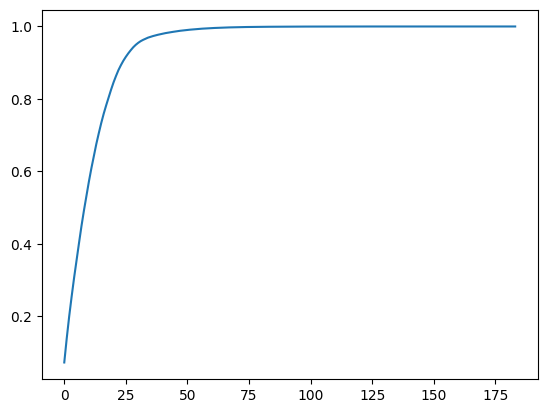

In [40]:
plt.plot(np.cumsum(pca.explained_variance_ratio_))
plt.show()

*I can see with the help of graph that at 35 pricipal components i can acheive explained 90 % variance therefore i will reduce the dataset dimensionality upto 25 cols*

In [53]:
pca = PCA(n_components=35)
X_train = pca.fit_transform(X_train)
X_test = pca.transform(X_test)

In [54]:
lr = LogisticRegression(max_iter=200)

model = lr.fit(X_train,y_train)

In [55]:
y_pred = model.predict(X_test)
accuracy_score(y_test,y_pred)

0.9782608695652174